# [Scene Recognition with Deep Learning](https://www.cc.gatech.edu/~hays/compvision/proj4/)
For this project we are going to focus on scene classification for 15 scene types with a state-of-the-art approach: deep learning. The task is also known as image classification. 

Basic learning objectives of this project:
1. Construct the fundamental pipeline for performing deep learning using PyTorch;
2. Understand the concepts behind different layers, optimizers, and learning schedules;
3. Experiment with different models and observe the performance.

The starter code is mostly initialized to 'placeholder' just so that the starter
code does not crash when run unmodified and you can get a preview of how
results are presented.

In [1]:
# flag to modify everything to run better on Colab; change it to true if you want to run on colab
use_colab = False

## Part 0: Setup for Colab
You can skip this part if you are not running your notebook on Colab.

### Upload code and unit tests

Once you have finished your code, run `python ./zip_for_colab.py` and all the required files and tests will be written to `cv_proj3.zip`.

Click the folder icon on the left of the colab UI, and click on the upload button right below the "Files" heading.

Run the cell below once your upload completes to extract your uploaded files.

In [2]:
# uncomment for running on colab
# !unzip -qq cv_proj3.zip -d ./
# !pip install -e .

In [3]:
# uncomment for running on colab
# import sys
# sys.path.insert(0, "/content/src")

### Preparation
We'll import the required functions and set up GPU computation. A GPU is **optional** for this project.

1. **Google Colab** - click `Runtime` → `Change runtime type`, select **T4 GPU** under *Hardware accelerator*, and click `Save`.

In [4]:
import os

import torch

from vision.runner import Trainer, MultiLabelTrainer
from vision.optimizer import get_optimizer
from vision.simple_net import SimpleNet
from vision.simple_net_final import SimpleNetFinal
from vision.my_resnet import MyResNet18
from vision.multilabel_resnet import MultilabelResNet18
from vision.data_transforms import (
    get_fundamental_transforms,
    get_fundamental_normalization_transforms,
    get_fundamental_augmentation_transforms,
    get_all_transforms,
)
from vision.stats_helper import compute_mean_and_std
from vision.confusion_matrix import (
    generate_confusion_data,
    generate_confusion_matrix,
    plot_confusion_matrix,
    get_pred_images_for_target,
    generate_and_plot_confusion_matrix,
    generate_and_plot_accuracy_table,
)
from vision.dl_utils import save_trained_model_weights

#comment below two line if issues while running on colab
%load_ext autoreload
%autoreload 2

In [5]:
from tests.utils import verify
from tests.test_stats_helper import test_mean_and_variance
from tests.test_image_loader import (
    test_dataset_length,
    test_unique_vals,
    test_class_values,
    test_load_img_from_path,
    test_multilabel_dataset_length,
    test_multilabel_unique_vals,
)
from tests.test_data_transforms import (
    test_fundamental_transforms,
    test_data_augmentation_transforms,
    test_data_augmentation_with_normalization_transforms,
)
from tests.test_dl_utils import (
    test_compute_accuracy,
    test_compute_loss,
    test_compute_multilabel_accuracy,
)
from tests.test_simple_net import test_simple_net
from tests.test_simple_net_final import test_simple_net_final
from tests.test_my_resnet import test_my_resnet
from tests.test_multilabel_resnet import test_multilabel_resnet
from tests.test_confusion_matrix import (
    test_generate_confusion_matrix,
    test_generate_confusion_matrix_normalized,
)

In [6]:
is_cuda = True
is_cuda = (
    is_cuda and torch.cuda.is_available()
)  # will turn off cuda if the machine doesnt have a GPU
print("Cuda available: ", is_cuda)

Cuda available:  False


In [7]:
is_apple_silicon = True
is_apple_silicon = is_apple_silicon and torch.backends.mps.is_available()
print(f"Apple silicon available: {is_apple_silicon}")

Apple silicon available: False


In [8]:
data_path = "./data/" if not use_colab else "./data/"
model_path = "../model_checkpoints/" if not use_colab else "./model_checkpoints/"

## Part 1: SimpleNet
To train a network in PyTorch, we need 4 components:
1. **Dataset** - an object which can load the data and labels given an index.
2. **Model** - an object that contains the network architecture definition.
3. **Loss function** - a function that measures how far the network output is from the ground truth label.
4. **Optimizer** - an object that optimizes the network parameters to reduce the loss value.

### Part 1.1: Datasets
Now let's create the **Datasets** object to be used later. Remember back in Project 1, we have initialized such a class to load 5 images? Here the task is similar: we have to load each image as well as it's classification label. The key idea is to store the paths to all the images in your dataset, and then be able to provide the image file path and its ground truth class id when given the index of a data example.

We will map the scene names (text) into indices 0 to 14 in the image loader. You can choose any mapping you want but once fixed, it has to be consistent throughout this notebook.

**TODO 1:** complete the `image_loader.py`

In [9]:
inp_size = (64, 64)
print("Testing your image loader (length):", verify(test_dataset_length))
print("Testing your image loader (values):", verify(test_unique_vals))
print("Testing your image loader (classes):", verify(test_class_values))
print("Testing your image loader (paths):", verify(test_load_img_from_path))

Testing your image loader (length): "Correct"
Testing your image loader (values): "Correct"
Testing your image loader (classes): "Correct"
Testing your image loader (paths): "Correct"


### Data transforms
**TODO 2:** complete the function `get_fundamental_transforms()` in `data_transforms.py` to compile the following fundamental transforms:
1. Resize the input image to the desired shape;
2. Convert it to a tensor.

In [10]:
print("Testing your fundamental data transforms: ", verify(test_fundamental_transforms))

Testing your fundamental data transforms:  "Correct"


### Part 1.2: Model
The data is ready! Now we are preparing to move to the actual core of deep learning: the architecture. To get you started in this part, simply define a **2-layer** model in the `simple_net.py`. Here by "2 layers" we mean **2 convolutional layers**, so you need to figure out the supporting utilities like ReLU, Max Pooling, and Fully Connected layers, and configure them with proper parameters to make the tensor flow.

You may refer to Figure 2 in proj3 handout for a sample network architecture (it's the architecture TAs used in their implementation and is sufficient to get you pass Part 1).

**TODO 3**: Do the following in ```simple_net.py```:
- ```self.conv_layers```
- ```self.fc_layers```
- ```forward()```

Leave the ```self.loss_criterion = None``` for now.

In [11]:
print("Testing your SimpleNet architecture: ", verify(test_simple_net))

Testing your SimpleNet architecture:  "Correct"


In [12]:
simple_model = SimpleNet()

### Loss function
When defining your model architecture, also initialize the `loss_criterion` variable there. Remeber this is multi-class classification problem, and choose the [appropriate loss function](https://pytorch.org/docs/stable/nn.html#loss-functions) might be useful here.

**TODO 4:** Assign a loss function to ```self.loss_criterion``` in ```simple_net.py```.

In [13]:
print(simple_model)

SimpleNet(
  (conv_layers): Sequential(
    (0): Conv2d(1, 10, kernel_size=(5, 5), stride=(1, 1))
    (1): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
    (2): ReLU()
    (3): Conv2d(10, 20, kernel_size=(5, 5), stride=(1, 1))
    (4): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
    (5): ReLU()
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=500, out_features=100, bias=True)
    (2): ReLU()
    (3): Linear(in_features=100, out_features=15, bias=True)
  )
  (loss_criterion): CrossEntropyLoss()
)


### Optimizer
**TODO 5:** **initialize the following cell with proper values for learning rate and weight decay** (you will need to come back and tune these values for better performance once the trainer section is done)

In [22]:
# TODO: add a decent initial setting and tune from there. The values are intentionally bad.
# We recommend using the adam optimizer and consulting Pytorch's adam documentation for default hyperparameter values.
optimizer_config = {"optimizer_type": "adam", "lr": 1e-3, "weight_decay": 1e-3}

**TODO 6:** complete the ```get_optimizer()``` function in ```optimizer.py```. The helper function accepts three basic configurations as defined below. Any other configuration is optional. *SGD* optimizer type should be supported, anything else is optional.

In [23]:
optimizer = get_optimizer(simple_model, optimizer_config)

### Part 1.3: Trainer

**TODO 7:** Next we define the trainer for the model; to start, we will need to do the following in ```dl_utils.py```:
- ```compute_loss()```: use the model's loss criterion and compute the corresponding loss between the model output and the ground-truth labels.
- ```compute_accuracy()```: compute the classification accuracy given the prediction logits and the ground-truth labels.

In [24]:
print("Testing your trainer (loss values): ", verify(test_compute_loss))
print("Testing your trainer (accuracy computation): ", verify(test_compute_accuracy))

Testing your trainer (loss values):  "Correct"
Testing your trainer (accuracy computation):  "Correct"


Then pass in the model, optimizer, transforms for both the training and testing datasets into the trainer, and proceed to the next cell to train it. If you have implemented everything correctly, you should be seeing a decreasing loss value.

**Note** in this project, we will be using the test set as the validation set (i.e. using it to guide our decisions about models and hyperparameters while training. In actual practise, you would not interact with the test set until reporting the final results.

**Note** that your CPU should be sufficient to handle the training process for all networks in this project, and the following training cells will take less than 5 minutes; you may also want to decrease the value for `num_epochs` and quickly experiment with your parameters. The default value of **30** is good enough to get you around the threshold for Part 1, and you are free to increase it a bit and adjust other parameters in this part.

In [32]:
# re-init the model so that the weights are all random
torch.manual_seed(0)
simple_model_base = SimpleNet()
optimizer = get_optimizer(simple_model_base, optimizer_config)

trainer = Trainer(
    data_dir=data_path,
    model=simple_model_base,
    optimizer=optimizer,
    model_dir=os.path.join(model_path, "simple_net"),
    train_data_transforms=get_fundamental_transforms(inp_size),
    val_data_transforms=get_fundamental_transforms(inp_size),
    batch_size=32,
    load_from_disk=False,
    cuda=is_cuda,
    mps=is_apple_silicon,
)

In [33]:
%%time
trainer.run_training_loop(num_epochs=30)

Epoch:1 Train Loss:2.6708 Val Loss: 2.7134 Train Accuracy: 0.1116 Validation Accuracy: 0.1100
Epoch:2 Train Loss:2.4598 Val Loss: 2.3637 Train Accuracy: 0.1829 Validation Accuracy: 0.1827
Epoch:3 Train Loss:2.1843 Val Loss: 2.2221 Train Accuracy: 0.2563 Validation Accuracy: 0.2307
Epoch:4 Train Loss:2.0797 Val Loss: 2.3032 Train Accuracy: 0.2938 Validation Accuracy: 0.2300
Epoch:5 Train Loss:2.0104 Val Loss: 2.0941 Train Accuracy: 0.3146 Validation Accuracy: 0.2867
Epoch:6 Train Loss:1.9504 Val Loss: 2.0420 Train Accuracy: 0.3320 Validation Accuracy: 0.3027
Epoch:7 Train Loss:1.8856 Val Loss: 1.9910 Train Accuracy: 0.3564 Validation Accuracy: 0.3373
Epoch:8 Train Loss:1.8394 Val Loss: 1.9621 Train Accuracy: 0.3866 Validation Accuracy: 0.3500
Epoch:9 Train Loss:1.7885 Val Loss: 1.9349 Train Accuracy: 0.4124 Validation Accuracy: 0.3580
Epoch:10 Train Loss:1.7442 Val Loss: 1.9427 Train Accuracy: 0.4174 Validation Accuracy: 0.3420
Epoch:11 Train Loss:1.7011 Val Loss: 1.8824 Train Accuracy:

After you have finished the training process, now plot out the loss and accuracy history. You can also check out the final accuracy for both training and testing data. Copy the accuracy plots and values onto the report, and answer the questions there. 

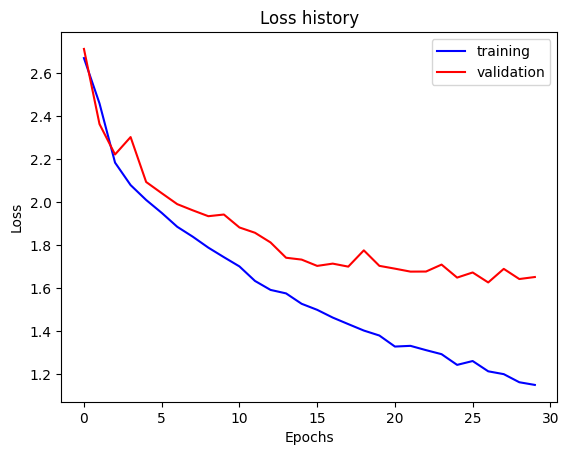

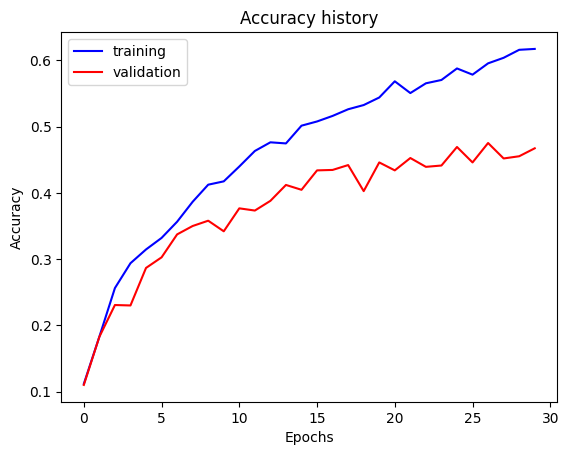

In [34]:
trainer.plot_loss_history()
trainer.plot_accuracy()

In [35]:
train_accuracy = trainer.train_accuracy_history[-1]
validation_accuracy = trainer.validation_accuracy_history[-1]
print(
    "Train Accuracy = {}; Validation Accuracy = {}".format(
        train_accuracy, validation_accuracy
    )
)

Train Accuracy = 0.6174204355308558; Validation Accuracy = 0.4673333333333333


**TODO 8:** Obtain **45%** validation accuracy to receive full credit for Part 1. You can go back to TODO 5 to tune your parameters using the following tips:
1. If the loss decreases very slowly, try increasing the value of the lr (learning rate).
2. Initially keep the value of weight decay (L2-regularization) very low.
3. Try to first adjust lr in multiples of 3 initially. When you are close to reasonable performance, do a more granular adjustment.
4. If you want to increase the validation accuracy by a little bit, try increasing the weight_decay to prevent overfitting. Do not use tricks from Section 6 just yet.

### Save the model for your SimpleNet
Once you are satisfied with the performance of your trained model, you need to save it so that you can upload it to Gradescope along with the other models.

We'll save the model to the current directory. If you're running locally on your computer, this should be in the `vision` folder, which is the desired location for uploading to gradescope.

If you are running on Colab, make sure you download the trained `.pt` files that will be generated. This process is similar to that of Project 3.
- Click on the folder icon in the left hand side menu
- Select the 3 dots next to the `<out_name>.pt` file that is generated and click download
- Store the file in the `vision` folder.

In [36]:
save_trained_model_weights(simple_model_base, out_dir="./src/vision")

## Part 2: SimpleNet with additional modifications

In Part 1 we implemented a basic CNN, but it doesn’t perform very well.  Let’s try a few tricks to see if we canimprove our model performance. You can start by copying your `SimpleNet` architecture from `simple_net.py` into `SimpleNetFinal` class in `simple_net_final.py`. 

**NOTE**: Before working on this part of the project, make sure to take a look at the report and write down your initial training and validation accuracy of you `SimpleNet` from the previous part. We will keep track of how these values change at each step of adding a few feature as we build up to `SimpleNetFinal`.

### Part 2.1: Problem 1 We don’t have enough training data. Let’s “jitter.”

We are going to increase our amount of training data by left-right mirroring and color jittering the training images during the learning process.

**TODO 9:** complete the `get_fundamental_augmentation_transforms()` function in `data_transforms.py`: first copy your existing fundamental transform implementation into this function, and then insert a couple of other transforms which help you do the above adjustment.                 

Useful functions:`transforms.RandomHorizontalFlip`, `transforms.ColorJitter`

In [37]:
print(
    "Testing your data transforms with data augmentation: ",
    verify(test_data_augmentation_transforms),
)

Testing your data transforms with data augmentation:  "Correct"


### Part 2.2: Problem 2 The images aren’t zero-centered and variance-normalized.

We are going to "zero-center" and "normalize" the dataset so that each entry has zero mean and the overall standard deviation is 1. 

**TODO 10**:  fill in the `compute_mean_and_std()` in `stats_helper.py` to compute the **mean** and **standard deviation** of both training and validation data.

In [38]:
print("Testing your mean and std computation: ", verify(test_mean_and_variance))
dataset_mean, dataset_std = compute_mean_and_std(data_path)

Testing your mean and std computation:  "Correct"


In [48]:
print("Dataset mean = {}, standard deviation = {}".format(dataset_mean, dataset_std))

Dataset mean = 0.455474856637557, standard deviation = 0.2531632763408797


**TODO 11**: complete the function `get_all_transforms()` function in `data_transforms.py` to normalize the input using the passed in mean andstandard deviation: you need to copy your implementation of `get_fundamental_augmentation_transforms()` into this function first.                 

In [49]:
print(
    "Testing your normalized data transforms: ",
    verify(test_data_augmentation_with_normalization_transforms),
)

Testing your normalized data transforms:  "Correct"


In [50]:
inp_size = (64, 64)

### Part 2.3-2.5: Problem 3 ~ 5: Modify the network.

**TODO 12:** modify the layers in the `SimpleNet` class in `simple_net.py`:
1. Add the dropout layer
2. Add one or two more blocks of “conv/pool/relu”.
3. Add a batch normalization layer after each convolutional layer (except for the last)

In [62]:
print("Testing your SimpleNetFinal architecture: ", verify(test_simple_net_final))

Testing your SimpleNetFinal architecture:  "Correct"


In [63]:
simple_model_final = SimpleNetFinal()
print(simple_model_final)

SimpleNetFinal(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Dropout(p=0.5, inplace=False)
    (13): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (14): ReLU()
    (15): MaxPool2d(kernel_s

Similar to the previous part, **initialize the following cell with proper values for learning rate and weight decay**.

In [64]:
# TODO: add a decent initial setting and tune from there. The values are intentionally bad.
# We recommend using the adam optimizer and consulting Pytorch's adam documentation for default hyperparameter values.
optimizer_config = {"optimizer_type": "adam", "lr": 1e-3, "weight_decay": 1e-3}

The following cell will take longer than Part 1.3, as now we have more data (and more variability), and the model is slightly more complicated than before as well; however, it should finish within 10~15 minutes anyway, and the default num_epochs is also good enough as a starting point for you to pass this part.

In [66]:
torch.manual_seed(0)
simple_model_final = SimpleNetFinal()
optimizer = get_optimizer(simple_model_final, optimizer_config)

trainer = Trainer(
    data_dir=data_path,
    model=simple_model_final,
    optimizer=optimizer,
    model_dir=os.path.join(model_path, "simple_model_final"),
    train_data_transforms=get_all_transforms(inp_size, [dataset_mean], [dataset_std]),
    val_data_transforms=get_fundamental_normalization_transforms(
        inp_size, [dataset_mean], [dataset_std]
    ),
    batch_size=32,
    load_from_disk=False,
    cuda=is_cuda,
    mps=is_apple_silicon,
)

In [67]:
%%time
torch.manual_seed(0)
trainer.run_training_loop(num_epochs=30)

Epoch:1 Train Loss:2.5100 Val Loss: 2.3044 Train Accuracy: 0.1678 Validation Accuracy: 0.2507
Epoch:2 Train Loss:2.1736 Val Loss: 2.0710 Train Accuracy: 0.2784 Validation Accuracy: 0.3087
Epoch:3 Train Loss:1.9055 Val Loss: 1.6627 Train Accuracy: 0.3575 Validation Accuracy: 0.4347
Epoch:4 Train Loss:1.7308 Val Loss: 1.5573 Train Accuracy: 0.4060 Validation Accuracy: 0.4947
Epoch:5 Train Loss:1.6202 Val Loss: 1.4731 Train Accuracy: 0.4372 Validation Accuracy: 0.5173
Epoch:6 Train Loss:1.5555 Val Loss: 1.4066 Train Accuracy: 0.4717 Validation Accuracy: 0.5260
Epoch:7 Train Loss:1.4775 Val Loss: 1.3048 Train Accuracy: 0.5012 Validation Accuracy: 0.5680
Epoch:8 Train Loss:1.4004 Val Loss: 1.4127 Train Accuracy: 0.5229 Validation Accuracy: 0.5200
Epoch:9 Train Loss:1.3495 Val Loss: 1.1791 Train Accuracy: 0.5464 Validation Accuracy: 0.5940
Epoch:10 Train Loss:1.2874 Val Loss: 1.2145 Train Accuracy: 0.5715 Validation Accuracy: 0.5893
Epoch:11 Train Loss:1.2593 Val Loss: 1.2208 Train Accuracy:

Similar to Part 1, now plot out the loss and accuracy history. Also copy the plots onto the report, and answer the questions accordingly.

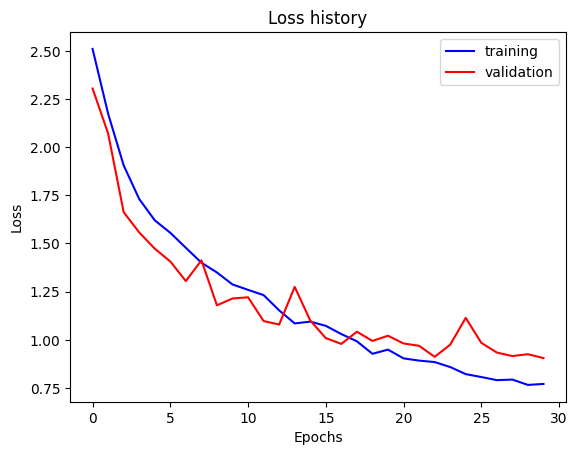

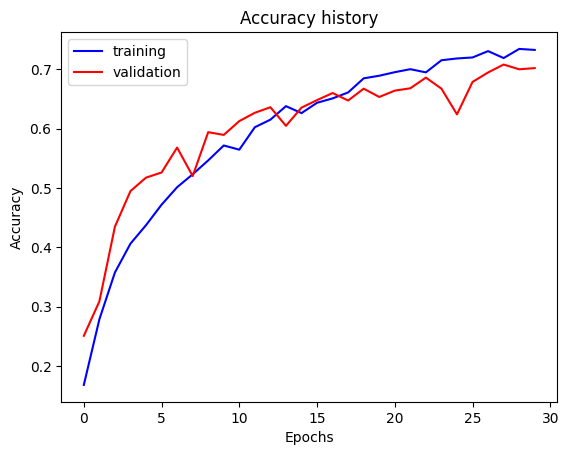

In [68]:
trainer.plot_loss_history()
trainer.plot_accuracy()

In [69]:
train_accuracy = trainer.train_accuracy_history[-1]
validation_accuracy = trainer.validation_accuracy_history[-1]
print(
    "Train Accuracy = {}; Validation Accuracy = {}".format(
        train_accuracy, validation_accuracy
    )
)

Train Accuracy = 0.7326633166627868; Validation Accuracy = 0.7020000001589457


**TODO 13:** Obtain a **55%** validation accuracy to receive full credit for Part 2.

### Save the model for your SimpleNetFinal

In [70]:
save_trained_model_weights(simple_model_final, out_dir="./src/vision")

### Part 2.6: Analysis using confusion matrix
A confusion matrix is a helpful tool for visualizing the performance of classification algorithms. Each row of the matrix represents the instances in a predicted class, while each column represents the instances in an actual class. The confusion matrix counts the number of instances of a given (target, prediction) pair. We are able to use this to understand the classification behaviour.

A confusion matrix can also be normalized by dividing each row by the total number of instances of the target class. This is helpful for comparing between large and small datasets, as well as when there is significant class imbalance.

**TODO 14:** Do the following to visualize the confusion matrix:

1. Implement the code to extract the predictions and targets from a model and a dataset
2. Implement the code to generate the confusion matrix, and its normalized form
3. Plot the confusion matrix and try to understand how your model is performing, and where it falls short. We'll use this later on for the report.

In [71]:
print(verify(test_generate_confusion_matrix))
print(verify(test_generate_confusion_matrix_normalized))

"Correct"
"Correct"


In [72]:
%%time
targets, predictions, class_labels = generate_confusion_data(
    trainer.model, trainer.val_dataset, use_cuda=is_cuda
)

CPU times: total: 35.3 s
Wall time: 12.4 s


In [73]:
confusion_matrix = generate_confusion_matrix(targets, predictions, len(class_labels))

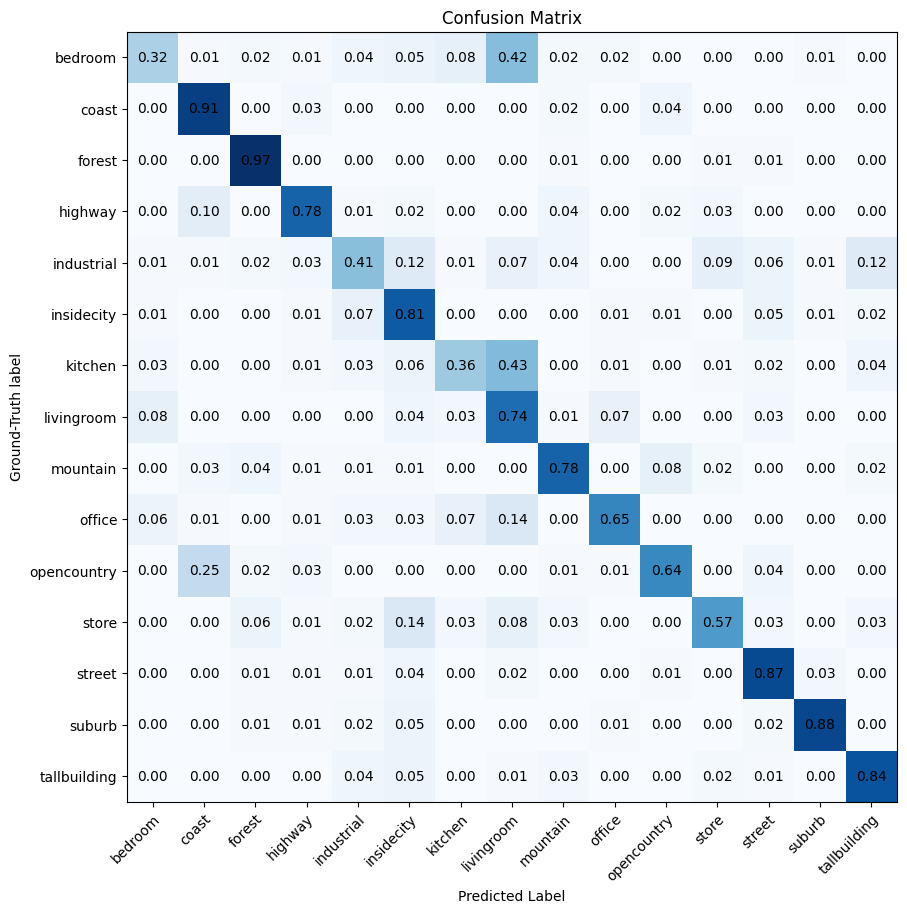

In [74]:
plot_confusion_matrix(confusion_matrix, class_labels)

### Part 2.7: Ablation study for the report (slide 3)

Each row adds one change on top of the previous one. All runs use the same seed, `optimizer_config` and number of epochs so the rows are comparable.

| Row | Model | Transforms |
|---|---|---|
| SimpleNet | Part 1 result | fundamental |
| + Jittering | `SimpleNet` | augmentation |
| + Normalization | `SimpleNet` | augmentation + normalization |
| + Dropout | `SimpleNetDropout` (below) | augmentation + normalization |
| + Deep | `SimpleNetDeep` (below) | augmentation + normalization |
| + Batch norm | `SimpleNetFinal` | Part 2 result above |

Run the `compute_mean_and_std` cell and the Part 2 optimizer cell before these cells. The models defined here are only for the report and are not part of the submission.

In [54]:
import torch.nn as nn


def run_ablation(make_model, train_tf, val_tf, name, epochs=30):
    torch.manual_seed(0)
    model = make_model()
    t = Trainer(
        data_dir=data_path,
        model=model,
        optimizer=get_optimizer(model, optimizer_config),
        model_dir=os.path.join(model_path, "ablation_" + name),
        train_data_transforms=train_tf,
        val_data_transforms=val_tf,
        batch_size=32,
        load_from_disk=False,
        cuda=is_cuda,
        mps=is_apple_silicon,
    )
    t.run_training_loop(num_epochs=epochs)
    print(
        f"{name}: train {t.train_accuracy_history[-1]:.4f}, "
        f"val {t.validation_accuracy_history[-1]:.4f}"
    )


print("optimizer_config:", optimizer_config)
norm_tr = get_all_transforms(inp_size, [dataset_mean], [dataset_std])
norm_va = get_fundamental_normalization_transforms(inp_size, [dataset_mean], [dataset_std])

optimizer_config: {'optimizer_type': 'adam', 'lr': 0.001, 'weight_decay': 0.001}


In [55]:
%%time
# Rows 2-3: SimpleNet + jittering, then + zero-centering & variance-normalization
run_ablation(
    SimpleNet,
    get_fundamental_augmentation_transforms(inp_size),
    get_fundamental_transforms(inp_size),
    "jitter",
)
run_ablation(SimpleNet, norm_tr, norm_va, "jitter_norm")

Epoch:1 Train Loss:2.6505 Val Loss: 2.6930 Train Accuracy: 0.1213 Validation Accuracy: 0.1187
Epoch:2 Train Loss:2.4270 Val Loss: 2.4254 Train Accuracy: 0.1755 Validation Accuracy: 0.1933
Epoch:3 Train Loss:2.3154 Val Loss: 2.3470 Train Accuracy: 0.2335 Validation Accuracy: 0.1940
Epoch:4 Train Loss:2.2085 Val Loss: 2.2036 Train Accuracy: 0.2566 Validation Accuracy: 0.2533
Epoch:5 Train Loss:2.1346 Val Loss: 2.1311 Train Accuracy: 0.2844 Validation Accuracy: 0.2640
Epoch:6 Train Loss:2.0526 Val Loss: 2.0328 Train Accuracy: 0.3166 Validation Accuracy: 0.3253
Epoch:7 Train Loss:1.9722 Val Loss: 1.9834 Train Accuracy: 0.3430 Validation Accuracy: 0.3273
Epoch:8 Train Loss:1.9342 Val Loss: 1.9007 Train Accuracy: 0.3605 Validation Accuracy: 0.3593
Epoch:9 Train Loss:1.8546 Val Loss: 1.8779 Train Accuracy: 0.3893 Validation Accuracy: 0.3587
Epoch:10 Train Loss:1.8048 Val Loss: 1.8683 Train Accuracy: 0.4020 Validation Accuracy: 0.3647
Epoch:11 Train Loss:1.7742 Val Loss: 1.8057 Train Accuracy:

In [56]:
class SimpleNetDropout(nn.Module):
    """Row 4: SimpleNet + dropout directly before the last conv layer"""

    def __init__(self):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 10, kernel_size=5),
            nn.MaxPool2d(kernel_size=3, stride=3),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Conv2d(10, 20, kernel_size=5),
            nn.MaxPool2d(kernel_size=3, stride=3),
            nn.ReLU(),
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(20 * 5 * 5, 100),
            nn.ReLU(),
            nn.Linear(100, 15),
        )
        self.loss_criterion = nn.CrossEntropyLoss(reduction="mean")

    def forward(self, x):
        return self.fc_layers(self.conv_layers(x))


class SimpleNetDeep(nn.Module):
    """Row 5: the SimpleNetFinal architecture without batch norm"""

    def __init__(self):
        super().__init__()

        def block(c_in, c_out):
            return [
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
            ]

        self.conv_layers = nn.Sequential(
            *block(1, 16),
            *block(16, 32),
            *block(32, 64),
            nn.Dropout(p=0.5),
            *block(64, 128),
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 15),
        )
        self.loss_criterion = nn.CrossEntropyLoss(reduction="mean")

    def forward(self, x):
        return self.fc_layers(self.conv_layers(x))

In [57]:
%%time
# Rows 4-5: + dropout, then + making the network deep
run_ablation(SimpleNetDropout, norm_tr, norm_va, "dropout")
run_ablation(SimpleNetDeep, norm_tr, norm_va, "deep")

Epoch:1 Train Loss:2.5839 Val Loss: 2.4314 Train Accuracy: 0.1447 Validation Accuracy: 0.2127
Epoch:2 Train Loss:2.1971 Val Loss: 2.1162 Train Accuracy: 0.2797 Validation Accuracy: 0.2940
Epoch:3 Train Loss:2.0099 Val Loss: 1.9589 Train Accuracy: 0.3390 Validation Accuracy: 0.3480
Epoch:4 Train Loss:1.8643 Val Loss: 1.9060 Train Accuracy: 0.3846 Validation Accuracy: 0.3567
Epoch:5 Train Loss:1.7789 Val Loss: 1.9012 Train Accuracy: 0.4191 Validation Accuracy: 0.3373
Epoch:6 Train Loss:1.7267 Val Loss: 1.8377 Train Accuracy: 0.4315 Validation Accuracy: 0.3980
Epoch:7 Train Loss:1.6697 Val Loss: 1.7550 Train Accuracy: 0.4466 Validation Accuracy: 0.4233
Epoch:8 Train Loss:1.5970 Val Loss: 1.6699 Train Accuracy: 0.4730 Validation Accuracy: 0.4527
Epoch:9 Train Loss:1.5603 Val Loss: 1.6671 Train Accuracy: 0.4905 Validation Accuracy: 0.4267
Epoch:10 Train Loss:1.5358 Val Loss: 1.6534 Train Accuracy: 0.4941 Validation Accuracy: 0.4667
Epoch:11 Train Loss:1.5044 Val Loss: 1.5731 Train Accuracy:

In [58]:
# Slide 6: parameter counts
count_params = lambda m: sum(p.numel() for p in m.parameters())
print("SimpleNet parameters:     ", count_params(SimpleNet()))
print("SimpleNetFinal parameters:", count_params(SimpleNetFinal()))

SimpleNet parameters:      56895
SimpleNetFinal parameters: 361583


## Part 3: ResNet
You can see that after the above adjustment, our model performance increases in terms of testing accuracy. Although the training accuracy drops, now it's closer to the testing values and that's more natural in terms of performance. But we are not satisfied with the final performance yet. Our model, in the end, is still a 2-layer SimpleNet and it might be capable of capturing some features, but could be improved a lot if we go **deeper**. In this part we are going to see the power of a famous model: ResNet18.

In [75]:
inp_size = (224, 224)

### Part 3.1 & 3.2: Fine-tuning the ResNet
Now let's define a ResNet which can be fit onto our dataset. PyTorch has provided us with pre-trained models like ResNet18, so what you want to do is to load the model first, and then adjust some of the layers such that it fits with our own dataset, instead of outputing scores to 1000 classes from the original ResNet18 model.


**TODO 15:** Switch to `my_resnet.py`, and copy the network architecture and weights of all but the last fc layers from the pretrained network.

After you have defined the correct architecture of the model, make some tweaks to the existing layers: **freeze** the **convolutional** layers and first 2 **linear** layers so we don't update the weights of them; more details can be found in the instruction webpage.

Note that you are allowed to add more layers/unfreeze more layers if you see fit.

In [76]:
print("Testing your ResNet architecture: ", verify(test_my_resnet))

Testing your ResNet architecture:  "Correct"


In [77]:
my_resnet = MyResNet18()
print(my_resnet)

MyResNet18(
  (conv_layers): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stat

In [78]:
# TODO: add a decent initial setting and tune from there. The values are intentionally bad.
# We recommend using the adam optimizer and consulting Pytorch's adam documentation for default hyperparameter values.
optimizer_config = {"optimizer_type": "adam", "lr": 1e-3, "weight_decay": 1e-4}

In [79]:
my_resnet = MyResNet18()
optimizer = get_optimizer(my_resnet, optimizer_config)

trainer = Trainer(
    data_dir=data_path,
    model=my_resnet,
    optimizer=optimizer,
    model_dir=os.path.join(model_path, "resnet18"),
    train_data_transforms=get_all_transforms(inp_size, [dataset_mean], [dataset_std]),
    val_data_transforms=get_fundamental_normalization_transforms(
        inp_size, [dataset_mean], [dataset_std]
    ),
    batch_size=32,
    load_from_disk=False,
    cuda=is_cuda,
    mps=is_apple_silicon,
)

The following training cell will take roughly 20 minutes or slightly more using CPU (but possibly under 5 minute using GPU depending on the batch size; the TAs got it within 3 minutes on a GTX1060 and within 1 minute on Apple M3 silicon).

In [80]:
%%time
trainer.run_training_loop(num_epochs=5)

Epoch:1 Train Loss:1.6195 Val Loss: 0.8871 Train Accuracy: 0.5497 Validation Accuracy: 0.8127
Epoch:2 Train Loss:0.7541 Val Loss: 0.5960 Train Accuracy: 0.8097 Validation Accuracy: 0.8493
Epoch:3 Train Loss:0.5559 Val Loss: 0.4832 Train Accuracy: 0.8536 Validation Accuracy: 0.8667
Epoch:4 Train Loss:0.4635 Val Loss: 0.4297 Train Accuracy: 0.8754 Validation Accuracy: 0.8787
Epoch:5 Train Loss:0.4147 Val Loss: 0.3757 Train Accuracy: 0.8777 Validation Accuracy: 0.8947
CPU times: total: 1h 32min 30s
Wall time: 32min 2s


You are required to pass a threshold of **85%** for this part. Copy the plots and values onto the report and answer questions accordingly.

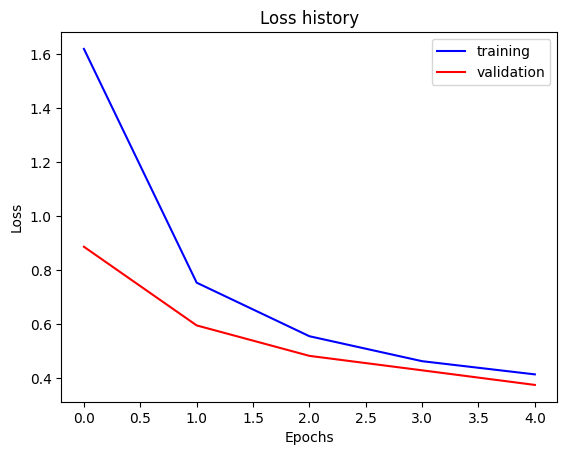

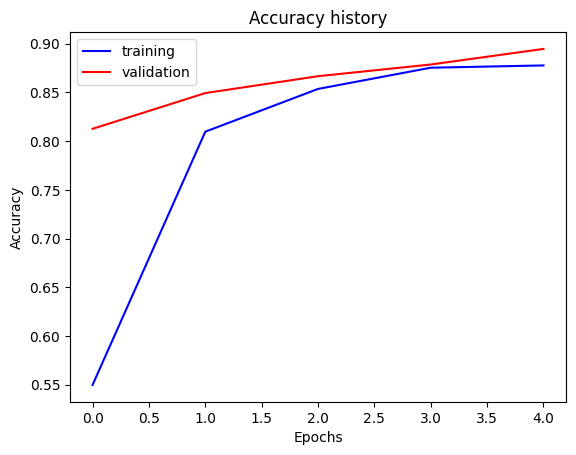

In [81]:
trainer.plot_loss_history()
trainer.plot_accuracy()

In [82]:
train_accuracy = trainer.train_accuracy_history[-1]
validation_accuracy = trainer.validation_accuracy_history[-1]
print(
    "Train Accuracy = {}; Validation Accuracy = {}".format(
        train_accuracy, validation_accuracy
    )
)

Train Accuracy = 0.8777219430485762; Validation Accuracy = 0.8946666669845581


**TODO 16**: Obtain a **85%** validation accuracy to receive full credits for Part 3.

### Save Trained MyResnet18 model

In [83]:
save_trained_model_weights(my_resnet, out_dir="./src/vision")

### Part 3.3 Visualize and Analyze Confusion Matrix

**TODO 17:** Visualize and analyze the confusion matrix.

You'll need to find an example of an image that is misclassified for the report. Use the confusion matrix and the `get_pred_images_for_target` function to help your analysis

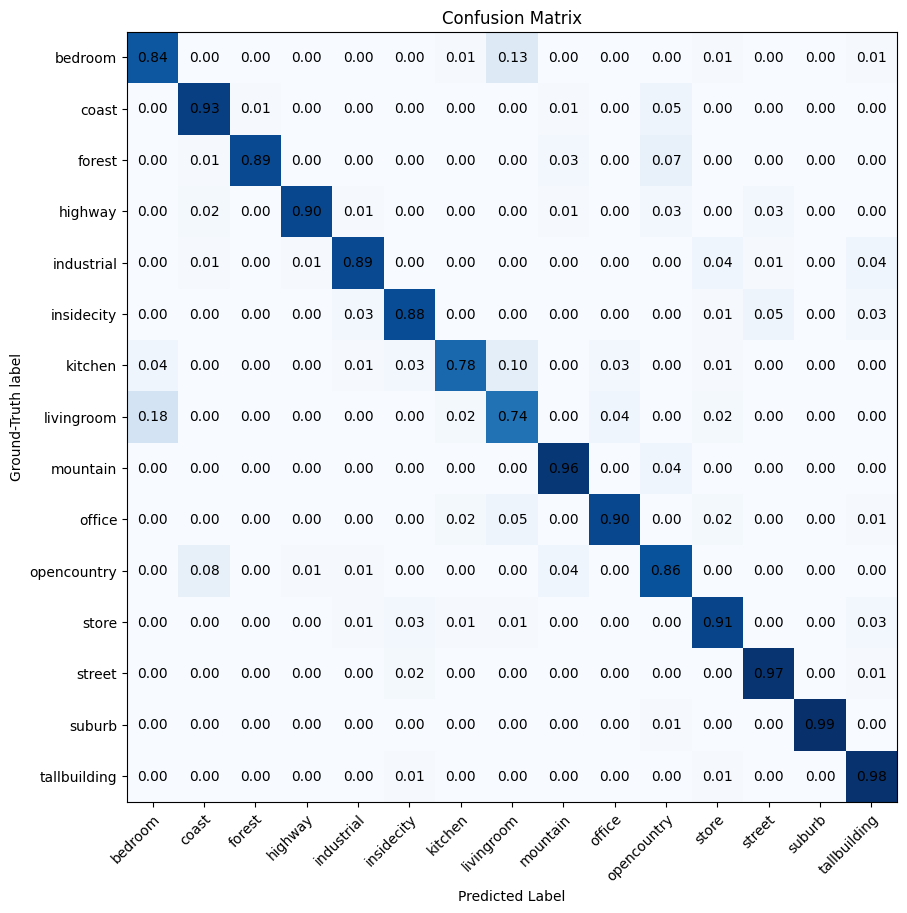

In [84]:
generate_and_plot_confusion_matrix(my_resnet, trainer.val_dataset, use_cuda=is_cuda)

26 misclassified livingroom images


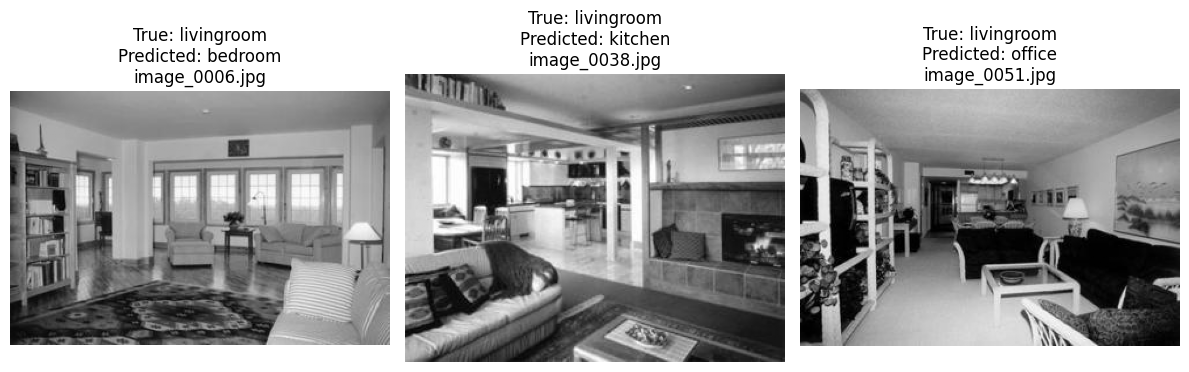

In [86]:
#########################
# Use this cell to visualize your images depending on the confusion matrix visualization
#########################
import os

import matplotlib.pyplot as plt
from PIL import Image

target_name = "livingroom"
num_images = 3

val_ds = trainer.val_dataset
idx_to_class = {idx: name for name, idx in val_ds.class_dict.items()}
target_idx = val_ds.class_dict[target_name]
device = next(my_resnet.parameters()).device

# Collect every misclassified image of the target class with its predicted label
misclassified = []
my_resnet.eval()
with torch.no_grad():
    for i, (path, label) in enumerate(val_ds.dataset):
        if label != target_idx:
            continue
        x, _ = val_ds[i]
        pred = my_resnet(x.unsqueeze(0).to(device)).argmax(dim=1).item()
        if pred != target_idx:
            misclassified.append((path, pred))
my_resnet.train()
print(f"{len(misclassified)} misclassified {target_name} images")

# Prefer examples with different predicted classes, then fill up with the rest
chosen, seen_preds = [], set()
for path, pred in misclassified:
    if pred not in seen_preds:
        chosen.append((path, pred))
        seen_preds.add(pred)
for item in misclassified:
    if len(chosen) >= num_images:
        break
    if item not in chosen:
        chosen.append(item)
chosen = chosen[:num_images]

fig, axes = plt.subplots(1, len(chosen), figsize=(4 * len(chosen), 4.5))
for ax, (path, pred) in zip(axes, chosen):
    ax.imshow(Image.open(path).convert("L"), cmap="gray")
    title_lines = [f"True: {target_name}", f"Predicted: {idx_to_class[pred]}", os.path.basename(path)]
    ax.set_title("\n".join(title_lines))
    ax.axis("off")
plt.tight_layout()
plt.show()


# Part 4: Multilabel Classification - Scene Attribute Prediction (Extra Credit)

Thus far, our convolutional neural network models are able to classify the class of the input image. This part of the project is focused on training a model that is capable of predicting attributes in images.

A subset of the above dataset containing images only from the 'coast', 'highway', 'mountain', 'opencountry', 'street' classes will be used. Target labels are represented as binary arrays corresponding to the following attributes:
<ul>
    <li> Clouds </li>
    <li> Water body </li>
    <li> People </li>
    <li> Animals </li>
    <li> Natural </li>
    <li> Man-made </li>
    <li> Vehicles </li>
</ul>

For example, if an input image of a natural scene has clouds, people and vehicles only, we expect an output of [1, 0, 1, 0, 1, 0, 1].

## Part 4.1 & 4.2 Model Architecture & Training
**TODO 18:** Switch to `multilabel_resnet.py`, and copy the network architecture and weights of all but the last fc layers from the pretrained network. Modify the network to obtain the desired output as shown above.

After you have defined the correct architecture of the model, make some tweaks to the existing layers: **freeze** the **convolutional** layers and first 2 **linear** layers so we don't update the weights of them; more details can be found in the instruction webpage.

Note that you are allowed to add more layers/unfreeze more layers if you see fit.

In [87]:
print("Testing your multilabel image loader (length):", verify(test_multilabel_dataset_length))
print("Testing your multilabel image loader (values):", verify(test_multilabel_unique_vals))

Testing your multilabel image loader (length): "Correct"
Testing your multilabel image loader (values): "Correct"


In [88]:
print("Testing your MultilabelResNet architecture: ", verify(test_multilabel_resnet))

Testing your MultilabelResNet architecture:  "Correct"


In [89]:
multi_resnet = MultilabelResNet18()
print(multi_resnet)

MultilabelResNet18(
  (conv_layers): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_runn

In [90]:
print("Testing your MultilabelResNet architecture: ", verify(test_multilabel_resnet))

Testing your MultilabelResNet architecture:  "Correct"


In [91]:
inp_size = (224, 224)

In [93]:
# TODO: add a decent initial setting and tune from there. The values are intentionally bad.
# We recommend using the adam optimizer and consulting Pytorch's adam documentation for default hyperparameter values.
optimizer_config = {"optimizer_type": "adam", "lr": 1e-3, "weight_decay": 1e-5}

In [95]:
multi_resnet = MultilabelResNet18()
optimizer = get_optimizer(multi_resnet, optimizer_config)

trainer = MultiLabelTrainer(
    data_dir=data_path,
    model=multi_resnet,
    optimizer=optimizer,
    model_dir=os.path.join(model_path, "multilabel_resnet18"),
    train_data_transforms=get_all_transforms(inp_size, [dataset_mean], [dataset_std]),
    val_data_transforms=get_fundamental_normalization_transforms(
        inp_size, [dataset_mean], [dataset_std]
    ),
    batch_size=32,
    load_from_disk=False,
    cuda=is_cuda,
    mps=is_apple_silicon,
)

In [96]:
%%time
trainer.run_training_loop(num_epochs=5)

Epoch:1 Train Loss:0.4881 Val Loss: 0.4130 Train Accuracy: 0.7647 Validation Accuracy: 0.8134
Epoch:2 Train Loss:0.3419 Val Loss: 0.3158 Train Accuracy: 0.8626 Validation Accuracy: 0.8863
Epoch:3 Train Loss:0.2930 Val Loss: 0.2863 Train Accuracy: 0.8949 Validation Accuracy: 0.8923
Epoch:4 Train Loss:0.2712 Val Loss: 0.2754 Train Accuracy: 0.8984 Validation Accuracy: 0.8971
Epoch:5 Train Loss:0.2543 Val Loss: 0.2616 Train Accuracy: 0.9042 Validation Accuracy: 0.9023
CPU times: total: 1h 13min 15s
Wall time: 29min 48s


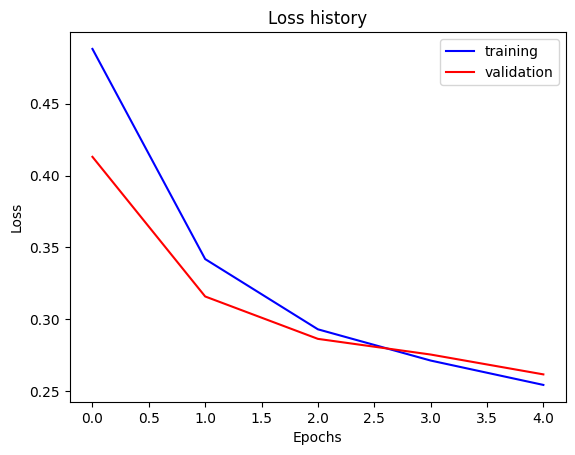

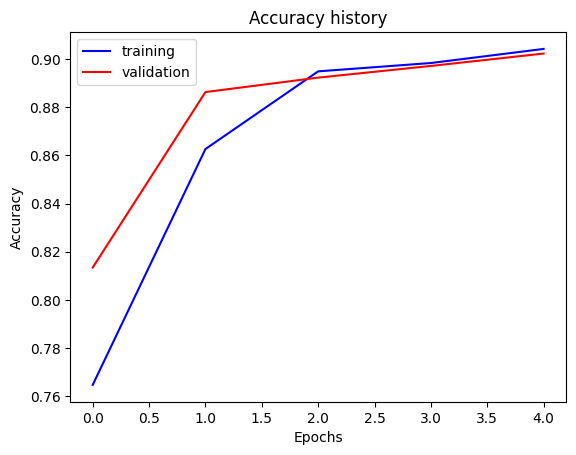

In [97]:
trainer.plot_loss_history()
trainer.plot_accuracy()

In [98]:
train_accuracy = trainer.train_accuracy_history[-1]
validation_accuracy = trainer.validation_accuracy_history[-1]
print(
    "Train Accuracy = {}; Validation Accuracy = {}".format(
        train_accuracy, validation_accuracy
    )
)

Train Accuracy = 0.9042044889966779; Validation Accuracy = 0.9022857227325439


**TODO 19**: Obtain a **90%** validation accuracy to receive full credits for Part 4.

### Save Trained MultilabelResnet18 model

In [99]:
save_trained_model_weights(multi_resnet, out_dir="./src/vision")

## 4.3 Visualize Results

Having an overall accuracy of >90% does not necessarily mean that the model is performing well. To truly analyze its performance in this multi-label classification task, the accuracy of each attribute should also be considered.

**TODO 20**: Complete the accuracy table for your multi-label classification model. 

In [100]:
print("Testing your multilabel accuracy table:", verify(test_compute_multilabel_accuracy))

Testing your multilabel accuracy table: "Correct"


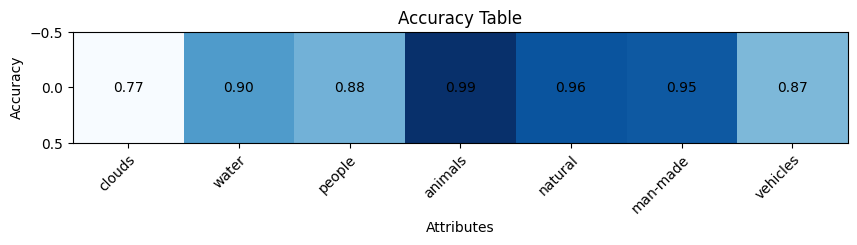

In [101]:
att_list = ['clouds', 'water', 'people', 'animals', 'natural', 'man-made', 'vehicles']

generate_and_plot_accuracy_table(
    multi_resnet, 
    trainer.val_dataset, 
    num_attributes=7,
    attribute_labels=att_list,
    use_cuda=is_cuda
)